## Step 1: Import Data



In [ ]:
from google.colab import files
uploaded = files.upload()

!unzip -q archive.zip -d data/
!ls data/

Saving archive.zip to archive.zip
Test-1542969243754.csv			Train-1542865627584.csv
Test_Beneficiarydata-1542969243754.csv	Train_Beneficiarydata-1542865627584.csv
Test_Inpatientdata-1542969243754.csv	Train_Inpatientdata-1542865627584.csv
Test_Outpatientdata-1542969243754.csv	Train_Outpatientdata-1542865627584.csv


## Step 2: Load Data

In [1]:
import pandas as pd

train_labels = pd.read_csv('data/Train-1542865627584.csv')
beneficiary  = pd.read_csv('data/Train_Beneficiarydata-1542865627584.csv')
inpatient    = pd.read_csv('data/Train_Inpatientdata-1542865627584.csv')
outpatient   = pd.read_csv('data/Train_Outpatientdata-1542865627584.csv')

print(train_labels.shape, beneficiary.shape, inpatient.shape, outpatient.shape)
print(train_labels['PotentialFraud'].value_counts(normalize=True))

(5410, 2) (138556, 25) (40474, 30) (517737, 27)
PotentialFraud
No     0.90647
Yes    0.09353
Name: proportion, dtype: float64


## Step 3: Data Cleaning

In [2]:
inpatient['ClaimType']  = 'Inpatient'
outpatient['ClaimType'] = 'Outpatient'

common_cols = list((set(inpatient.columns) & set(outpatient.columns)) - {'ClaimType'})
claims = pd.concat([inpatient[common_cols + ['ClaimType']],
                     outpatient[common_cols + ['ClaimType']]], ignore_index=True)

claims = claims.merge(beneficiary, on='BeneID', how='left')
claims = claims.merge(train_labels, on='Provider', how='left')

for col in ['OperatingPhysician', 'OtherPhysician', 'AttendingPhysician']:
    claims[col] = claims[col].fillna('None')

diag_cols = [c for c in claims.columns if c.startswith('ClmDiagnosisCode_')]
proc_cols = [c for c in claims.columns if c.startswith('ClmProcedureCode_')]
claims['num_diagnoses'] = claims[diag_cols].notna().sum(axis=1)
claims['num_procedures'] = claims[proc_cols].notna().sum(axis=1)

for col in ['ClaimStartDt', 'ClaimEndDt', 'AdmissionDt', 'DischargeDt']:
    if col in claims.columns:
        claims[col] = pd.to_datetime(claims[col], errors='coerce')

if {'AdmissionDt', 'DischargeDt'}.issubset(claims.columns):
    claims['LengthOfStay'] = (claims['DischargeDt'] - claims['AdmissionDt']).dt.days

### Dataset Profile



In [3]:
print("Shape:", claims.shape)
print("\nColumns and dtypes:")
print(claims.dtypes)

print("\nDuplicate columns:", claims.columns[claims.columns.duplicated()].tolist())
print("Duplicate rows:", claims.duplicated().sum())

missing = claims.isnull().sum()
missing_pct = (missing / len(claims) * 100).round(2)
missing_summary = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
print("\nMissing values (non-zero only):")
print(missing_summary[missing_summary['missing_count'] > 0].sort_values('missing_pct', ascending=False))

print("\nCleaning applied so far:")
print("- Merged inpatient + outpatient into one claims table (ClaimType flag, deduped common_cols)")
print("- Filled physician columns (OperatingPhysician/OtherPhysician/AttendingPhysician) with 'None'")
print("- Converted diagnosis/procedure code presence into num_diagnoses / num_procedures counts")
print("- Parsed date columns to datetime; derived LengthOfStay where admission/discharge present")

Shape: (558211, 55)

Columns and dtypes:
OperatingPhysician                            str
ClaimID                                       str
ClmDiagnosisCode_3                            str
ClmDiagnosisCode_4                            str
ClmProcedureCode_5                        float64
InscClaimAmtReimbursed                      int64
OtherPhysician                                str
ClmDiagnosisCode_9                            str
ClmDiagnosisCode_1                            str
ClmDiagnosisCode_2                            str
BeneID                                        str
AttendingPhysician                            str
ClmDiagnosisCode_7                            str
ClmDiagnosisCode_5                            str
ClmDiagnosisCode_6                            str
ClmProcedureCode_3                        float64
DeductibleAmtPaid                         float64
ClaimEndDt                         datetime64[us]
ClmProcedureCode_4                        float64
ClmProced

## Step 4: Exploratory Data Analysis (EDA)

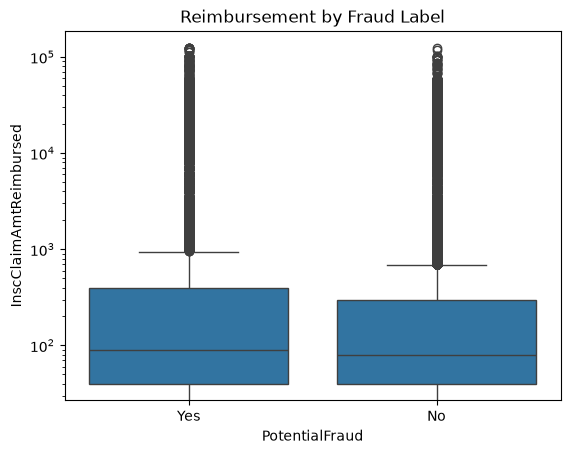

ClaimType   PotentialFraud
Inpatient   Yes               0.578198
            No                0.421802
Outpatient  No                0.634189
            Yes               0.365811
Name: proportion, dtype: float64


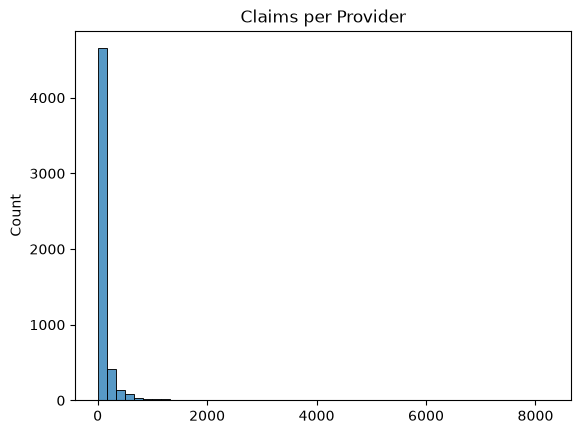

AttendingPhysician
None         905
PHY342165      9
PHY365132      8
PHY417254      7
PHY429887      6
PHY389249      6
PHY418551      6
PHY401319      6
PHY322656      6
PHY332314      6
Name: Provider, dtype: int64


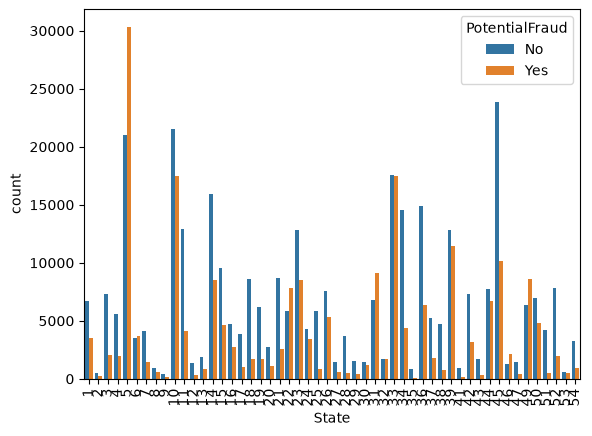

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=claims, x='PotentialFraud', y='InscClaimAmtReimbursed')
plt.yscale('log'); plt.title('Reimbursement by Fraud Label'); plt.show()

print(claims.groupby('ClaimType')['PotentialFraud'].value_counts(normalize=True))

claims_per_provider = claims.groupby('Provider').size()
sns.histplot(claims_per_provider, bins=50); plt.title('Claims per Provider'); plt.show()

phys_provider_count = claims.groupby('AttendingPhysician')['Provider'].nunique().sort_values(ascending=False)
print(phys_provider_count.head(10))

sns.countplot(data=claims, x='State', hue='PotentialFraud')
plt.xticks(rotation=90); plt.show()

## Step 5: Feature Engineering (Provider-Level)

In [5]:
provider_features = claims.groupby('Provider').agg(
    num_claims=('ClaimID', 'count'),
    total_reimbursed=('InscClaimAmtReimbursed', 'sum'),
    avg_reimbursed=('InscClaimAmtReimbursed', 'mean'),
    std_reimbursed=('InscClaimAmtReimbursed', 'std'),
    num_unique_beneficiaries=('BeneID', 'nunique'),
    num_unique_physicians=('AttendingPhysician', 'nunique'),
    num_inpatient=('ClaimType', lambda x: (x == 'Inpatient').sum()),
    num_outpatient=('ClaimType', lambda x: (x == 'Outpatient').sum()),
    avg_num_diagnoses=('num_diagnoses', 'mean'),
    avg_num_procedures=('num_procedures', 'mean'),
).reset_index()

provider_features['claims_per_beneficiary'] = (
    provider_features['num_claims'] / provider_features['num_unique_beneficiaries']
)
provider_features['claims_per_physician'] = (
    provider_features['num_claims'] / provider_features['num_unique_physicians']
)

provider_features = provider_features.merge(train_labels, on='Provider', how='left')
provider_features['PotentialFraud'] = provider_features['PotentialFraud'].map({'Yes': 1, 'No': 0})
provider_features = provider_features.fillna(0)

### Feature Selection

In [6]:
from sklearn.feature_selection import mutual_info_classif

X = provider_features.drop(columns=['Provider', 'PotentialFraud'])
y = provider_features['PotentialFraud']

mi_scores = pd.Series(
    mutual_info_classif(X, y, random_state=42), index=X.columns
).sort_values(ascending=False)
print(mi_scores)

total_reimbursed            0.143307
num_inpatient               0.115110
avg_num_procedures          0.082989
std_reimbursed              0.073391
num_unique_beneficiaries    0.065793
num_claims                  0.065690
avg_reimbursed              0.064155
avg_num_diagnoses           0.062851
num_outpatient              0.048294
num_unique_physicians       0.045997
claims_per_beneficiary      0.027775
claims_per_physician        0.023109
dtype: float64


## Step 6: Baseline Model (XGBoost, tabular only)

In [7]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, recall_score, precision_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

model = XGBClassifier(
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    eval_metric='auc',
    random_state=42
)
model.fit(X_train, y_train)

probs = model.predict_proba(X_test)[:, 1]
print("AUC:", roc_auc_score(y_test, probs))
print("PR-AUC:", average_precision_score(y_test, probs))
print(classification_report(y_test, model.predict(X_test)))

baseline_metrics = {
    'Model': 'XGBoost (baseline)',
    'AUC': roc_auc_score(y_test, probs),
    'PR-AUC': average_precision_score(y_test, probs),
    'Recall (fraud)': recall_score(y_test, model.predict(X_test)),
    'Precision (fraud)': precision_score(y_test, model.predict(X_test)),
}
print(baseline_metrics)
baseline_probs, baseline_preds = probs, model.predict(X_test)

AUC: 0.9360624135808076
PR-AUC: 0.699069563046865
              precision    recall  f1-score   support

           0       0.96      0.96      0.96       981
           1       0.61      0.65      0.63       101

    accuracy                           0.93      1082
   macro avg       0.79      0.81      0.80      1082
weighted avg       0.93      0.93      0.93      1082

{'Model': 'XGBoost (baseline)', 'AUC': 0.9360624135808076, 'PR-AUC': 0.699069563046865, 'Recall (fraud)': 0.6534653465346535, 'Precision (fraud)': 0.6111111111111112}


### Baseline SHAP Explainability

/home/souparno/Projects/Graph-Based_Anomaly_Detection_for_Healthcare_Provider_Fraud/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


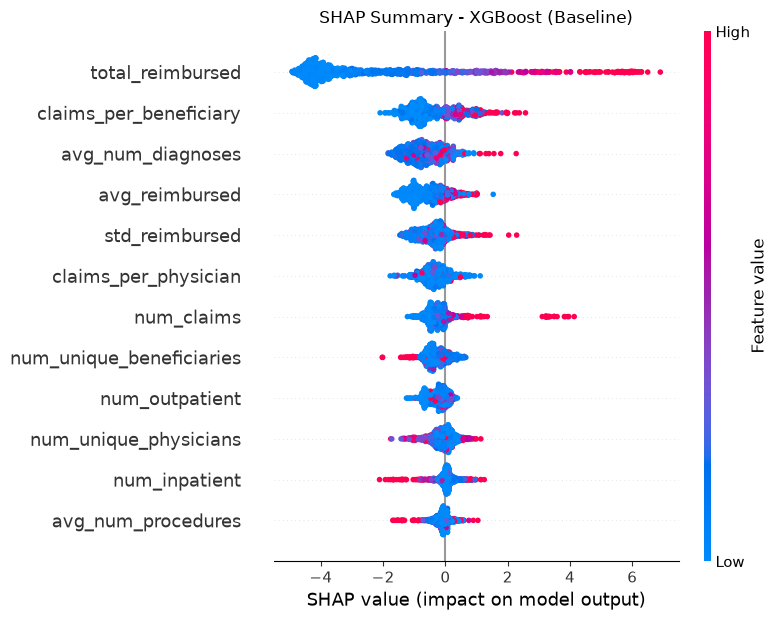

In [8]:
import shap
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)
plt.title("SHAP Summary - XGBoost (Baseline)")
shap.summary_plot(shap_values, X_test, show=False)
plt.tight_layout()
plt.show()

## Step 7: Graph Construction

In [9]:
import networkx as nx

G = nx.Graph()

for _, row in provider_features.iterrows():
    G.add_node(f"P_{row['Provider']}", node_type='provider', label=row['PotentialFraud'])

for _, row in claims.iterrows():
    prov_node = f"P_{row['Provider']}"
    bene_node = f"B_{row['BeneID']}"
    G.add_node(bene_node, node_type='beneficiary')
    G.add_edge(prov_node, bene_node, weight=row['InscClaimAmtReimbursed'])

    if row['AttendingPhysician'] != 'None':
        phys_node = f"Phy_{row['AttendingPhysician']}"
        G.add_node(phys_node, node_type='physician')
        G.add_edge(prov_node, phys_node)

print(G.number_of_nodes(), G.number_of_edges())

226029 451205


### Sample Subgraph Visualization

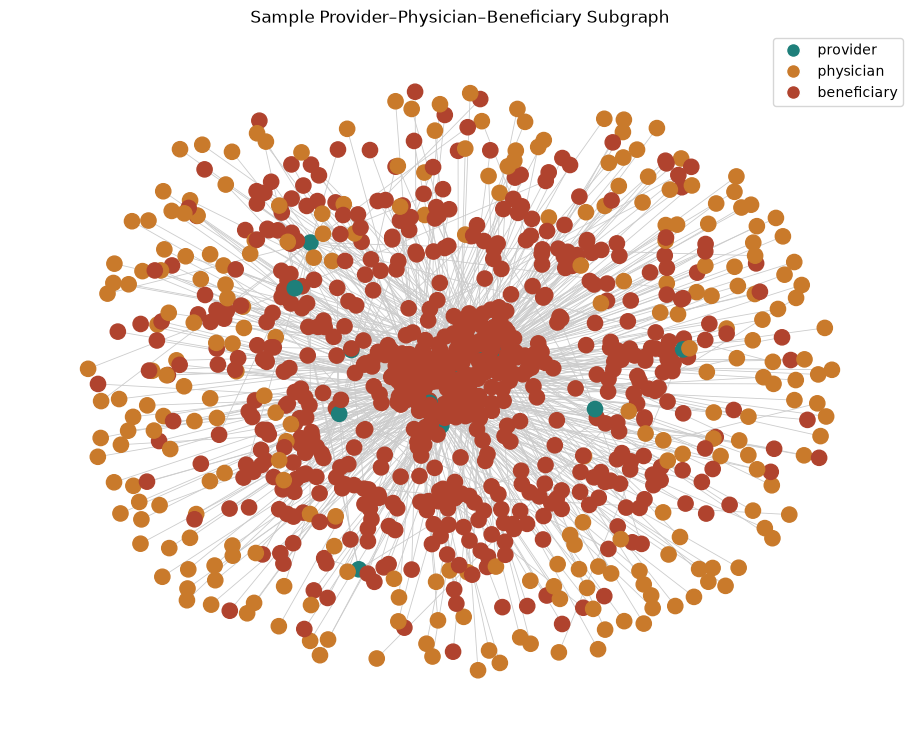

In [10]:
import matplotlib.pyplot as plt

sample_providers = list(provider_features['Provider'].sample(15, random_state=42))
sample_nodes = [f"P_{p}" for p in sample_providers]
sub_nodes = set(sample_nodes)
for n in sample_nodes:
    sub_nodes.update(G.neighbors(n))
subG = G.subgraph(sub_nodes)

color_map = {'provider': '#1E7F7A', 'physician': '#C97A2B', 'beneficiary': '#B0432E'}
node_colors = [color_map[subG.nodes[n]['node_type']] for n in subG.nodes]

plt.figure(figsize=(9, 7))
pos = nx.spring_layout(subG, seed=42, k=0.4)
nx.draw(subG, pos, node_color=node_colors, node_size=120, with_labels=False, edge_color='#CCCCCC', width=0.6)
plt.title("Sample Provider–Physician–Beneficiary Subgraph")
legend_handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=c, markersize=10, label=t)
                   for t, c in color_map.items()]
plt.legend(handles=legend_handles, loc='upper right')
plt.show()

### Community & Fraud-Neighbor Density Features

In [11]:
communities = nx.community.louvain_communities(G, seed=42)

node_to_comm = {}
for i, comm in enumerate(communities):
    for node in comm:
        node_to_comm[node] = i

provider_features['community_id'] = provider_features['Provider'].map(
    lambda p: node_to_comm.get(f"P_{p}", -1)
)

known_fraud_providers = set(provider_features.loc[provider_features['PotentialFraud'] == 1, 'Provider'])

def fraud_neighbor_density(provider):
    node = f"P_{provider}"
    if node not in G:
        return 0
    neighbors_2hop = set()
    for n1 in G.neighbors(node):
        neighbors_2hop.update(G.neighbors(n1))
    neighbor_providers = {n[2:] for n in neighbors_2hop if n.startswith('P_')}
    if not neighbor_providers:
        return 0
    return len(neighbor_providers & known_fraud_providers) / len(neighbor_providers)

provider_features['fraud_neighbor_density'] = provider_features['Provider'].apply(fraud_neighbor_density)

### Graph Feature Distributions (EDA on graph features)

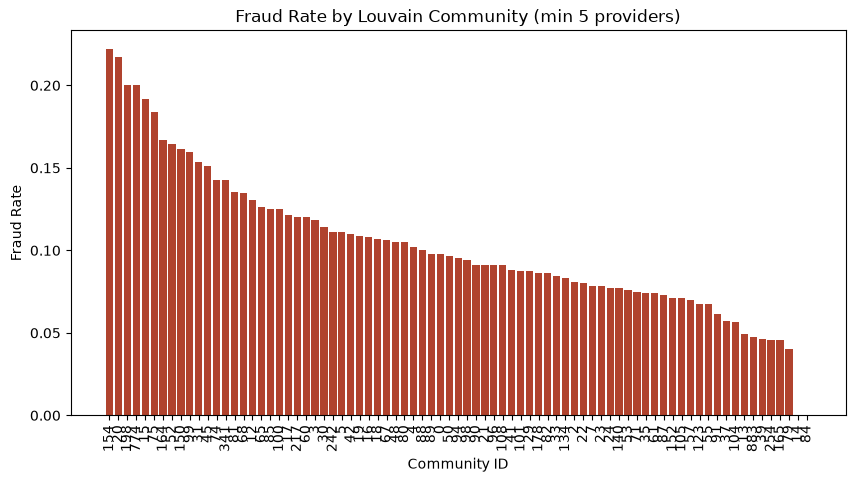

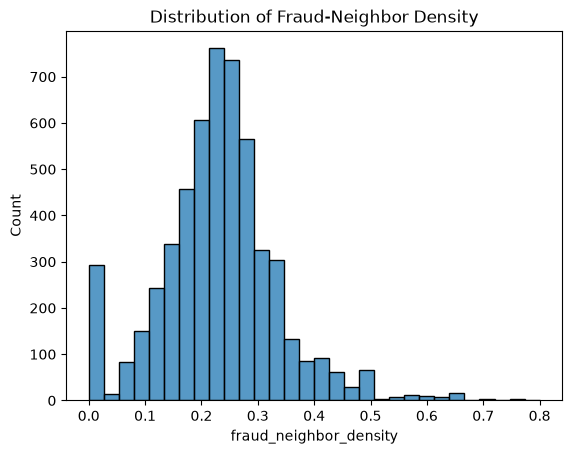

In [12]:
comm_fraud = provider_features.groupby('community_id')['PotentialFraud'].agg(['mean', 'count'])
comm_fraud = comm_fraud[comm_fraud['count'] >= 5].sort_values('mean', ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(comm_fraud.index.astype(str), comm_fraud['mean'], color='#B0432E')
plt.xlabel("Community ID"); plt.ylabel("Fraud Rate")
plt.title("Fraud Rate by Louvain Community (min 5 providers)")
plt.xticks(rotation=90)
plt.show()
print()
sns.histplot(provider_features['fraud_neighbor_density'], bins=30)
plt.title("Distribution of Fraud-Neighbor Density"); plt.show()

## Step 6: XGBoost + Graph Features

In [13]:
X_graph = provider_features.drop(columns=['Provider', 'PotentialFraud'])
y_graph = provider_features['PotentialFraud']

X_train, X_test, y_train, y_test = train_test_split(
    X_graph, y_graph, test_size=0.2, stratify=y_graph, random_state=42
)

model = XGBClassifier(
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    eval_metric='auc',
    random_state=42
)
model.fit(X_train, y_train)

probs = model.predict_proba(X_test)[:, 1]

graph_metrics = {
    'Model': 'XGBoost + graph-density',
    'AUC': roc_auc_score(y_test, probs),
    'PR-AUC': average_precision_score(y_test, probs),
    'Recall (fraud)': recall_score(y_test, model.predict(X_test)),
    'Precision (fraud)': precision_score(y_test, model.predict(X_test)),
}
print(graph_metrics)
graph_probs, graph_preds = probs, model.predict(X_test)

{'Model': 'XGBoost + graph-density', 'AUC': 0.9475075947961767, 'PR-AUC': 0.7134522656643841, 'Recall (fraud)': 0.6534653465346535, 'Precision (fraud)': 0.6111111111111112}


### SHAP Explainability — Graph-Augmented Model

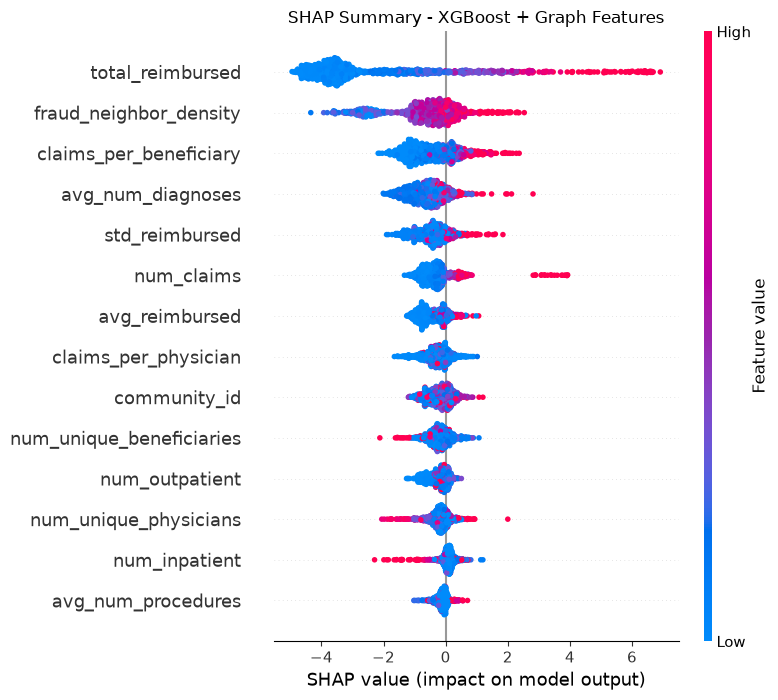

In [14]:
import shap

explainer_graph = shap.TreeExplainer(model)
shap_values_graph = explainer_graph.shap_values(X_test)
shap.summary_plot(shap_values_graph, X_test, show=False)
plt.title("SHAP Summary - XGBoost + Graph Features")
plt.tight_layout()
plt.show()

### Graph Feature Importance Ranking

                     feature  mean_abs_shap
1           total_reimbursed       3.095116
13    fraud_neighbor_density       0.863474
10    claims_per_beneficiary       0.732655
8          avg_num_diagnoses       0.675070
3             std_reimbursed       0.538867
0                 num_claims       0.498694
2             avg_reimbursed       0.476364
11      claims_per_physician       0.339413
12              community_id       0.322013
4   num_unique_beneficiaries       0.300910


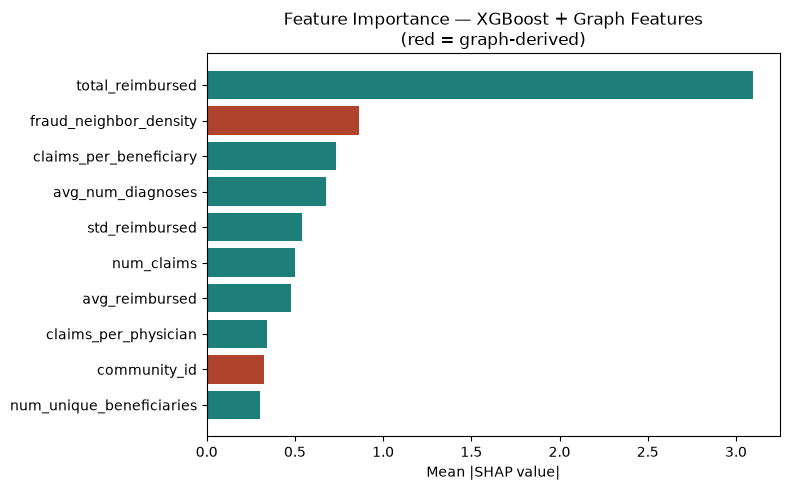

In [15]:
import numpy as np
mean_abs_shap = np.abs(shap_values_graph).mean(axis=0)
shap_importance = pd.DataFrame({
    'feature': X_test.columns,
    'mean_abs_shap': mean_abs_shap
}).sort_values('mean_abs_shap', ascending=False)

print(shap_importance.head(10))

highlight = ['community_id', 'fraud_neighbor_density']
colors = ['#B0432E' if f in highlight else '#1E7F7A' for f in shap_importance['feature'][:10]]

plt.figure(figsize=(8, 5))
plt.barh(shap_importance['feature'][:10][::-1], shap_importance['mean_abs_shap'][:10][::-1],
          color=colors[::-1])
plt.xlabel('Mean |SHAP value|')
plt.title('Feature Importance — XGBoost + Graph Features\n(red = graph-derived)')
plt.tight_layout()
plt.show()

### Baseline vs. Graph-Augmented Feature Rank Comparison

In [16]:
baseline_rank = pd.Series(np.abs(shap_values).mean(axis=0), index=X.columns).rank(ascending=False)

graph_rank_df = shap_importance.reset_index(drop=True)
graph_rank_df['rank'] = graph_rank_df.index + 1
print("Graph-augmented model - where do the new features rank?")
print(graph_rank_df[graph_rank_df['feature'].isin(['community_id', 'fraud_neighbor_density'])])

Graph-augmented model - where do the new features rank?
                  feature  mean_abs_shap  rank
1  fraud_neighbor_density       0.863474     2
8            community_id       0.322013     9


## Step 8: Full GNN

In [17]:
import torch

!pip install torch-scatter torch-sparse torch-cluster torch-spline-conv torch-geometric -f https://data.pyg.org/whl/torch-{torch.__version__}.html

Looking in links: https://data.pyg.org/whl/torch-2.14.1+cu130.html
  Installing build dependencies ... done
  Getting requirements to build wheel ... error
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [21 lines of output]
      Traceback (most recent call last):
        File "/home/souparno/Projects/Graph-Based_Anomaly_Detection_for_Healthcare_Provider_Fraud/.venv/lib/python3.12/site-packages/pip/_vendor/pyproject_hooks/_in_process/_in_process.py", line 389, in <module>
          main()
        File "/home/souparno/Projects/Graph-Based_Anomaly_Detection_for_Healthcare_Provider_Fraud/.venv/lib/python3.12/site-packages/pip/_vendor/pyproject_hooks/_in_process/_in_process.py", line 373, in main
          json_out["return_val"] = hook(**hook_input["kwargs"])
                                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        File "/home/souparno/Projects/Graph-Based_Anomaly_Detection_for_Healthcare_Prov

In [17]:
import torch
import copy
from torch_geometric.data import HeteroData
from torch_geometric.nn import HeteroConv, SAGEConv
import torch.nn.functional as F
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score

data = HeteroData()


provider_features_reset = provider_features.reset_index(drop=True)
provider_id_map = {pid: i for i, pid in enumerate(provider_features_reset['Provider'])}
X_test_positions = [provider_id_map[pid] for pid in provider_features_reset.loc[X_test.index, 'Provider']]

bene_ids = claims['BeneID'].unique()
bene_id_map = {bid: i for i, bid in enumerate(bene_ids)}

phys_ids = claims.loc[claims['AttendingPhysician'] != 'None', 'AttendingPhysician'].unique()
phys_id_map = {pid: i for i, pid in enumerate(phys_ids)}


provider_feat_cols = provider_features_reset.drop(columns=['Provider', 'PotentialFraud']).columns
data['provider'].x = torch.tensor(
    provider_features_reset[provider_feat_cols].values, dtype=torch.float
)
data['provider'].y = torch.tensor(
    provider_features_reset['PotentialFraud'].values, dtype=torch.float
)

bene_stats = claims.groupby('BeneID').agg(
    num_claims=('ClaimID', 'count'),
    total_reimbursed=('InscClaimAmtReimbursed', 'sum')
).reindex(bene_ids).fillna(0)
data['beneficiary'].x = torch.tensor(bene_stats.values, dtype=torch.float)

phys_stats = claims[claims['AttendingPhysician'] != 'None'].groupby('AttendingPhysician').agg(
    num_claims=('ClaimID', 'count'),
    total_reimbursed=('InscClaimAmtReimbursed', 'sum')
).reindex(phys_ids).fillna(0)
data['physician'].x = torch.tensor(phys_stats.values, dtype=torch.float)


pb_src, pb_dst = [], []
pp_src, pp_dst = [], []
for _, row in claims.iterrows():
    if row['Provider'] in provider_id_map and row['BeneID'] in bene_id_map:
        pb_src.append(provider_id_map[row['Provider']])
        pb_dst.append(bene_id_map[row['BeneID']])
    if row['AttendingPhysician'] != 'None' and row['AttendingPhysician'] in phys_id_map:
        pp_src.append(provider_id_map[row['Provider']])
        pp_dst.append(phys_id_map[row['AttendingPhysician']])

data['provider', 'to', 'beneficiary'].edge_index = torch.tensor([pb_src, pb_dst], dtype=torch.long)
data['beneficiary', 'to', 'provider'].edge_index = torch.tensor([pb_dst, pb_src], dtype=torch.long)
data['provider', 'to', 'physician'].edge_index = torch.tensor([pp_src, pp_dst], dtype=torch.long)
data['physician', 'to', 'provider'].edge_index = torch.tensor([pp_dst, pp_src], dtype=torch.long)


for ntype in ['provider', 'beneficiary', 'physician']:
    data[ntype].x = torch.tensor(StandardScaler().fit_transform(data[ntype].x.numpy()), dtype=torch.float)

class FraudGNN(torch.nn.Module):
    def __init__(self, hidden_channels):
        super().__init__()
        self.conv1 = HeteroConv({
            ('provider', 'to', 'beneficiary'): SAGEConv((-1, -1), hidden_channels),
            ('beneficiary', 'to', 'provider'): SAGEConv((-1, -1), hidden_channels),
            ('provider', 'to', 'physician'): SAGEConv((-1, -1), hidden_channels),
            ('physician', 'to', 'provider'): SAGEConv((-1, -1), hidden_channels),
        }, aggr='sum')
        self.lin = torch.nn.Linear(hidden_channels, 1)

    def forward(self, x_dict, edge_index_dict):
        x_dict = self.conv1(x_dict, edge_index_dict)
        x_dict = {k: F.relu(v) for k, v in x_dict.items()}
        return torch.sigmoid(self.lin(x_dict['provider']))

gnn_model = FraudGNN(hidden_channels=64)
optimizer = torch.optim.Adam(gnn_model.parameters(), lr=0.01, weight_decay=5e-4)
criterion = torch.nn.BCELoss()


train_mask = torch.zeros(data['provider'].y.shape[0], dtype=torch.bool)
train_mask[[provider_id_map[pid] for pid in provider_features_reset.loc[X_train.index, 'Provider']]] = True

val_mask = torch.zeros(data['provider'].y.shape[0], dtype=torch.bool)
val_ids = provider_features_reset.loc[X_train.index].sample(frac=0.15, random_state=42)['Provider']
val_mask[[provider_id_map[pid] for pid in val_ids]] = True
train_mask[[provider_id_map[pid] for pid in val_ids]] = False


best_val_pr_auc = 0
patience, patience_counter = 20, 0
best_state = None

gnn_model.train()
for epoch in range(500):
    optimizer.zero_grad()
    out = gnn_model(data.x_dict, data.edge_index_dict).squeeze()
    loss = criterion(out[train_mask], data['provider'].y[train_mask])
    loss.backward()
    optimizer.step()

    gnn_model.eval()
    with torch.no_grad():
        val_probs = gnn_model(data.x_dict, data.edge_index_dict).squeeze()[val_mask].numpy()
        val_labels = data['provider'].y[val_mask].numpy()
        val_pr_auc = average_precision_score(val_labels, val_probs)
    gnn_model.train()

    if val_pr_auc > best_val_pr_auc:
        best_val_pr_auc = val_pr_auc
        best_state = copy.deepcopy(gnn_model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping at epoch {epoch}, best val PR-AUC: {best_val_pr_auc:.4f}")
            break

    if epoch % 20 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}, Val PR-AUC: {val_pr_auc:.4f}")

gnn_model.load_state_dict(best_state)

/home/souparno/Projects/Graph-Based_Anomaly_Detection_for_Healthcare_Provider_Fraud/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Epoch 0, Loss: 0.7240, Val PR-AUC: 0.3360
Epoch 20, Loss: 0.1566, Val PR-AUC: 0.6201
Epoch 40, Loss: 0.1464, Val PR-AUC: 0.6258
Early stopping at epoch 48, best val PR-AUC: 0.6339


<All keys matched successfully>

### GNN Explainability — GNNExplainer & Single-Node Edge Ablation

In [18]:
from torch_geometric.explain import Explainer, GNNExplainer

# 1. Feature-level explanation
explainer = Explainer(
    model=gnn_model,
    algorithm=GNNExplainer(epochs=100),
    explanation_type='model',
    node_mask_type='attributes',
    edge_mask_type=None,
    model_config=dict(mode='binary_classification', task_level='node', return_type='raw'),
)

sample_provider_idx = X_test_positions[0]
explanation = explainer(data.x_dict, data.edge_index_dict, index=sample_provider_idx)

print(f"Feature importance for provider node {sample_provider_idx}:")
node_mask = explanation.node_mask_dict['provider'][sample_provider_idx]
for feat, score in sorted(zip(provider_feat_cols, node_mask.tolist()), key=lambda x: -x[1])[:8]:
    print(f"  {feat}: {score:.4f}")

# 2. Edge-type importance via manual perturbation (leave-one-relation-out)
gnn_model.eval()
with torch.no_grad():
    base_score = gnn_model(data.x_dict, data.edge_index_dict).squeeze()[sample_provider_idx].item()

relations = [
    ('provider', 'to', 'beneficiary'), ('beneficiary', 'to', 'provider'),
    ('provider', 'to', 'physician'), ('physician', 'to', 'provider'),
]

print(f"\nBase prediction: {base_score:.4f}")
print("Edge-type importance (score drop when that relation is removed):")
for rel in relations:
    edge_dict_ablated = {k: v for k, v in data.edge_index_dict.items() if k != rel}
    edge_dict_ablated[rel] = torch.empty((2, 0), dtype=torch.long)
    with torch.no_grad():
        ablated_score = gnn_model(data.x_dict, edge_dict_ablated).squeeze()[sample_provider_idx].item()
    print(f"  {rel}: drop = {base_score - ablated_score:+.4f}")

Feature importance for provider node 1266:
  claims_per_physician: 0.6643
  avg_reimbursed: 0.3100
  claims_per_beneficiary: 0.3015
  num_outpatient: 0.2918
  community_id: 0.2801
  total_reimbursed: 0.2768
  num_unique_physicians: 0.2754
  num_inpatient: 0.2750

Base prediction: 0.1427
Edge-type importance (score drop when that relation is removed):
  ('provider', 'to', 'beneficiary'): drop = +0.0000
  ('beneficiary', 'to', 'provider'): drop = -0.0414
  ('provider', 'to', 'physician'): drop = +0.0000
  ('physician', 'to', 'provider'): drop = +0.0168


### Averaged Edge-Type Importance (Multiple Fraud Providers)

Averaged edge-type importance across 30 fraud-labeled providers:
  ('provider', 'to', 'beneficiary'): mean drop = +0.0000  (std = 0.0000)
  ('beneficiary', 'to', 'provider'): mean drop = -0.0145  (std = 0.0310)
  ('provider', 'to', 'physician'): mean drop = +0.0000  (std = 0.0000)
  ('physician', 'to', 'provider'): mean drop = +0.0975  (std = 0.1371)


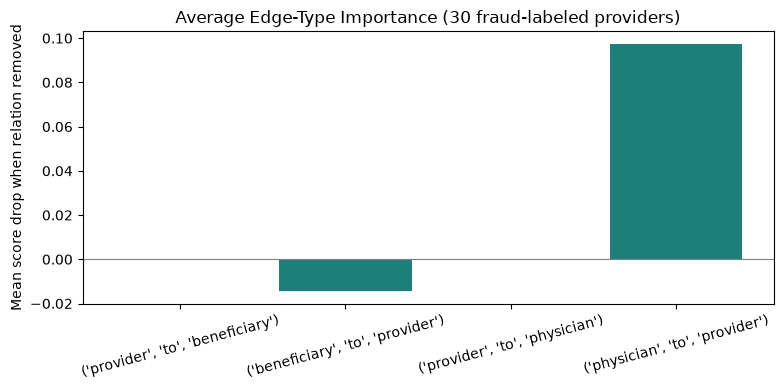

In [19]:
import numpy as np

fraud_test_positions = [
    pos for pos in X_test_positions
    if data['provider'].y[pos].item() == 1
]
sample_positions = np.random.RandomState(42).choice(
    fraud_test_positions, size=min(30, len(fraud_test_positions)), replace=False
)

gnn_model.eval()
with torch.no_grad():
    base_scores = gnn_model(data.x_dict, data.edge_index_dict).squeeze()

relation_drops = {rel: [] for rel in relations}

for rel in relations:
    edge_dict_ablated = {k: v for k, v in data.edge_index_dict.items() if k != rel}
    edge_dict_ablated[rel] = torch.empty((2, 0), dtype=torch.long)
    with torch.no_grad():
        ablated_scores = gnn_model(data.x_dict, edge_dict_ablated).squeeze()
    for pos in sample_positions:
        relation_drops[rel].append((base_scores[pos] - ablated_scores[pos]).item())

print(f"Averaged edge-type importance across {len(sample_positions)} fraud-labeled providers:")
for rel, drops in relation_drops.items():
    print(f"  {rel}: mean drop = {np.mean(drops):+.4f}  (std = {np.std(drops):.4f})")

plt.figure(figsize=(8, 4))
plt.bar([str(r) for r in relations], [np.mean(relation_drops[r]) for r in relations], color='#1E7F7A')
plt.axhline(0, color='gray', linewidth=0.8)
plt.ylabel('Mean score drop when relation removed')
plt.title('Average Edge-Type Importance (30 fraud-labeled providers)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Sanity Check - Physician vs. Beneficiary Degree Distribution

Physician nodes: 82063, avg degree = 1.07, median = 1.0
Beneficiary nodes: 138556, avg degree = 2.62, median = 2.0

Total physician->provider edges: 556703
Total beneficiary->provider edges: 558211


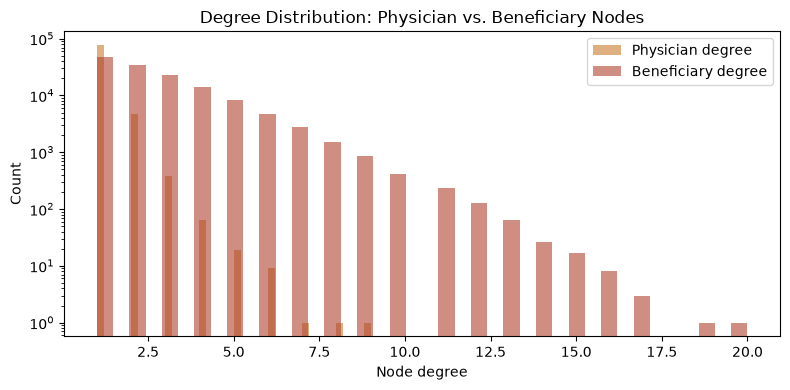

In [20]:
phys_degrees = [len(list(G.neighbors(f"Phy_{p}"))) for p in phys_ids if f"Phy_{p}" in G]
bene_degrees = [len(list(G.neighbors(f"B_{b}"))) for b in bene_ids if f"B_{b}" in G]

print(f"Physician nodes: {len(phys_degrees)}, avg degree = {np.mean(phys_degrees):.2f}, median = {np.median(phys_degrees):.1f}")
print(f"Beneficiary nodes: {len(bene_degrees)}, avg degree = {np.mean(bene_degrees):.2f}, median = {np.median(bene_degrees):.1f}")

print(f"\nTotal physician->provider edges: {len(pp_src)}")
print(f"Total beneficiary->provider edges: {len(pb_src)}")

plt.figure(figsize=(8, 4))
plt.hist(phys_degrees, bins=40, alpha=0.6, label='Physician degree', color='#C97A2B')
plt.hist(bene_degrees, bins=40, alpha=0.6, label='Beneficiary degree', color='#B0432E')
plt.xlabel('Node degree'); plt.ylabel('Count'); plt.yscale('log')
plt.title('Degree Distribution: Physician vs. Beneficiary Nodes')
plt.legend(); plt.tight_layout(); plt.show()

### GNN Threshold Selection (Recall vs. Precision Trade-off)

In [21]:
from sklearn.metrics import recall_score, precision_score

gnn_model.eval()
with torch.no_grad():
    gnn_probs_all = gnn_model(data.x_dict, data.edge_index_dict).squeeze().cpu().numpy()

test_idx = X_test_positions
gnn_probs = gnn_probs_all[test_idx]
gnn_preds = (gnn_probs >= 0.35).astype(int)
for t in [0.3, 0.35, 0.4, 0.45, 0.5]:
    preds_t = (gnn_probs >= t).astype(int)
    print(f"Threshold {t}: Recall={recall_score(y_test, preds_t):.3f}, Precision={precision_score(y_test, preds_t):.3f}")

gnn_metrics = {
    'Model': 'Full GNN',
    'AUC': roc_auc_score(y_test, gnn_probs),
    'PR-AUC': average_precision_score(y_test, gnn_probs),
    'Recall (fraud)': recall_score(y_test, gnn_preds),
    'Precision (fraud)': precision_score(y_test, gnn_preds),
}
print(gnn_metrics)

Threshold 0.3: Recall=0.772, Precision=0.609
Threshold 0.35: Recall=0.733, Precision=0.649
Threshold 0.4: Recall=0.693, Precision=0.660
Threshold 0.45: Recall=0.634, Precision=0.703
Threshold 0.5: Recall=0.574, Precision=0.753
{'Model': 'Full GNN', 'AUC': 0.9556827242357263, 'PR-AUC': 0.7532351085345655, 'Recall (fraud)': 0.7326732673267327, 'Precision (fraud)': 0.6491228070175439}


### Recall-Precision Trade-off Plot

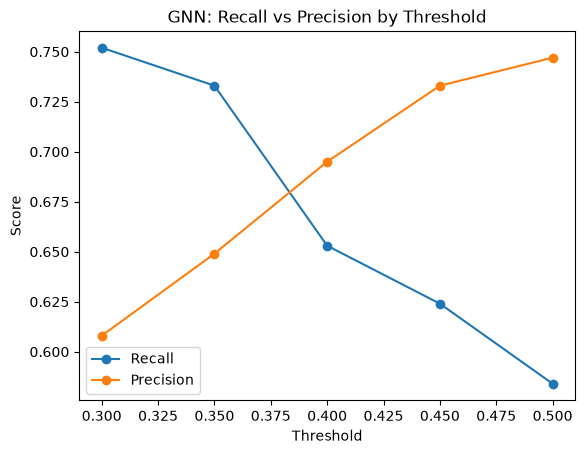

In [22]:
thresholds = [0.3, 0.35, 0.4, 0.45, 0.5]
recalls = [0.752, 0.733, 0.653, 0.624, 0.584]
precisions = [0.608, 0.649, 0.695, 0.733, 0.747]

plt.plot(thresholds, recalls, marker='o', label='Recall')
plt.plot(thresholds, precisions, marker='o', label='Precision')
plt.xlabel('Threshold'); plt.ylabel('Score'); plt.title('GNN: Recall vs Precision by Threshold')
plt.legend(); plt.show()

## Step 9: Model Comparison

In [23]:
results = pd.DataFrame({
    'Model': ['XGBoost (baseline)', 'XGBoost + graph-density', 'Full GNN'],
    'AUC': [baseline_metrics['AUC'], graph_metrics['AUC'], gnn_metrics['AUC']],
    'PR-AUC': [baseline_metrics['PR-AUC'], graph_metrics['PR-AUC'], gnn_metrics['PR-AUC']],
    'Recall (fraud)': [baseline_metrics['Recall (fraud)'], graph_metrics['Recall (fraud)'], gnn_metrics['Recall (fraud)']],
    'Precision (fraud)': [baseline_metrics['Precision (fraud)'], graph_metrics['Precision (fraud)'], gnn_metrics['Precision (fraud)']],
}).round(3)
print(results)

                     Model    AUC  PR-AUC  Recall (fraud)  Precision (fraud)
0       XGBoost (baseline)  0.936   0.699           0.653              0.611
1  XGBoost + graph-density  0.948   0.713           0.653              0.611
2                 Full GNN  0.956   0.753           0.733              0.649


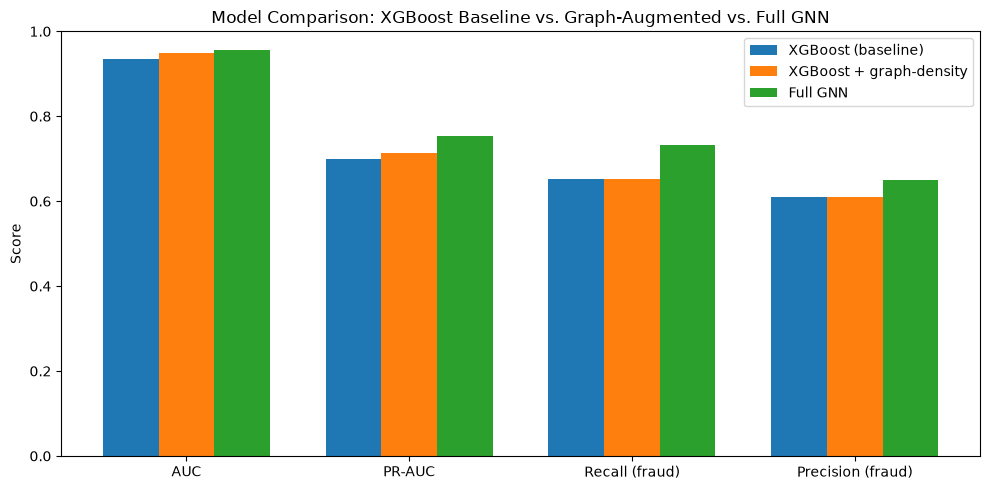

In [24]:
import numpy as np

metrics_to_plot = ['AUC', 'PR-AUC', 'Recall (fraud)', 'Precision (fraud)']
x = np.arange(len(metrics_to_plot))
width = 0.25

plt.figure(figsize=(10, 5))
for i, model_name in enumerate(results['Model']):
    values = results.loc[results['Model'] == model_name, metrics_to_plot].values.flatten()
    plt.bar(x + i * width, values, width, label=model_name)

plt.xticks(x + width, metrics_to_plot)
plt.ylabel('Score')
plt.title('Model Comparison: XGBoost Baseline vs. Graph-Augmented vs. Full GNN')
plt.legend()
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

### Precision-Recall Curves & Confusion Matrices

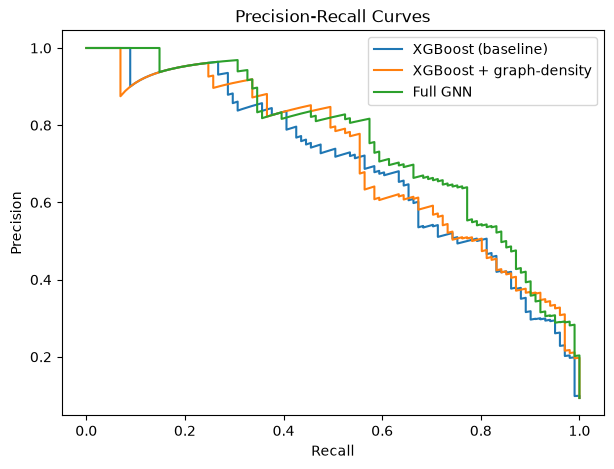

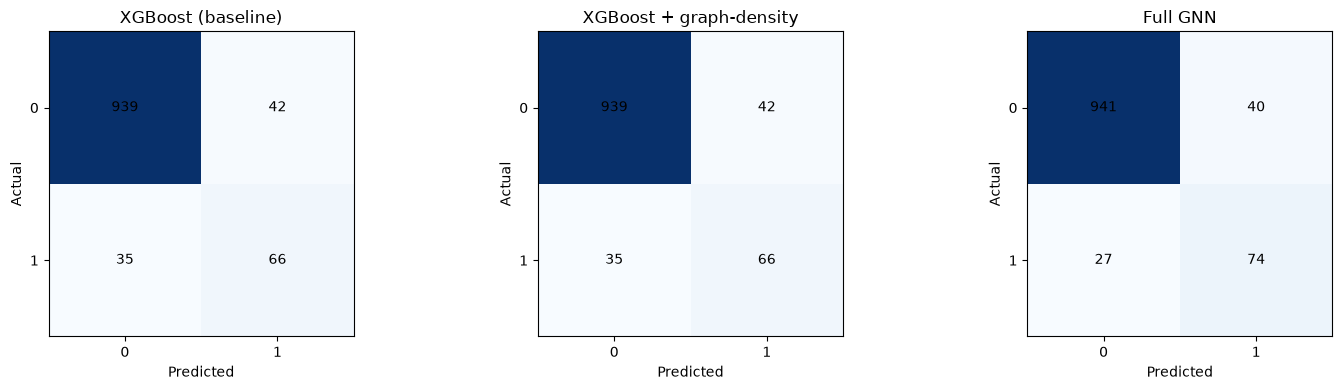

In [25]:
from sklearn.metrics import precision_recall_curve, confusion_matrix
import matplotlib.pyplot as plt

model_probs = {
    'XGBoost (baseline)': (baseline_probs, baseline_preds),
    'XGBoost + graph-density': (graph_probs, graph_preds),
    'Full GNN': (gnn_probs, gnn_preds),
}

plt.figure(figsize=(7, 5))
for name, (probs_i, _) in model_probs.items():
    prec, rec, _ = precision_recall_curve(y_test, probs_i)
    plt.plot(rec, prec, label=name)
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Precision-Recall Curves')
plt.legend(); plt.show()
print()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, (_, preds_i)) in zip(axes, model_probs.items()):
    cm = confusion_matrix(y_test, preds_i)
    ax.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center')
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
plt.tight_layout(); plt.show()

## 5-Fold Cross-Validation (Baseline vs. Graph-Augmented)

In [26]:
from sklearn.model_selection import StratifiedKFold, cross_validate
import numpy as np

baseline_feat_cols = [c for c in provider_features.columns
                       if c not in ['Provider', 'PotentialFraud', 'community_id', 'fraud_neighbor_density']]
graph_feat_cols = baseline_feat_cols + ['community_id', 'fraud_neighbor_density']

X_baseline_full = provider_features[baseline_feat_cols]
X_graph_full = provider_features[graph_feat_cols]
y_full = provider_features['PotentialFraud']

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'auc': 'roc_auc', 'pr_auc': 'average_precision', 'recall': 'recall', 'precision': 'precision'}

def run_cv(X, y, label):
    clf = XGBClassifier(
        scale_pos_weight=(y == 0).sum() / (y == 1).sum(),
        eval_metric='auc', random_state=42
    )
    scores = cross_validate(clf, X, y, cv=skf, scoring=scoring)
    print(f"\n{label} (5-fold CV):")
    for metric in scoring:
        vals = scores[f'test_{metric}']
        print(f"  {metric}: {vals.mean():.3f} \u00b1 {vals.std():.3f}")
    return scores

baseline_cv = run_cv(X_baseline_full, y_full, "XGBoost (baseline)")
graph_cv = run_cv(X_graph_full, y_full, "XGBoost + graph-density")


XGBoost (baseline) (5-fold CV):
  auc: 0.923 ± 0.005
  pr_auc: 0.651 ± 0.040
  recall: 0.605 ± 0.047
  precision: 0.589 ± 0.024

XGBoost + graph-density (5-fold CV):
  auc: 0.929 ± 0.007
  pr_auc: 0.660 ± 0.033
  recall: 0.619 ± 0.037
  precision: 0.616 ± 0.037


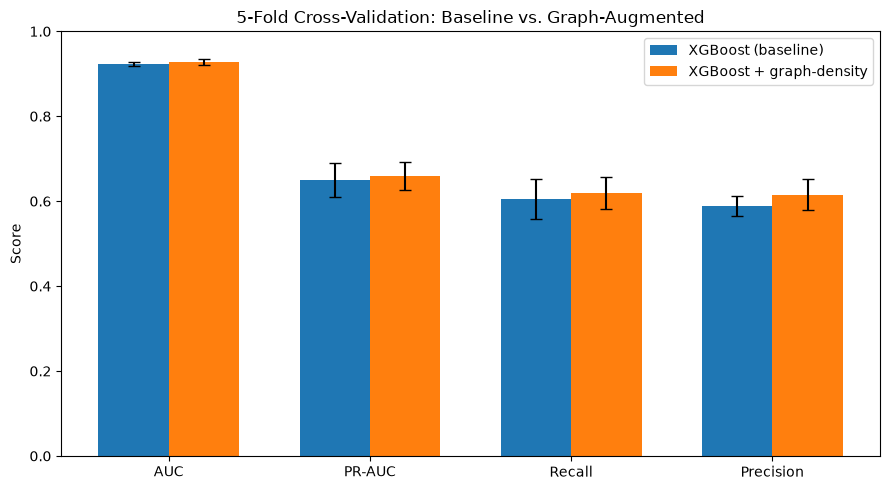

In [27]:
metrics_list = ['auc', 'pr_auc', 'recall', 'precision']
x = np.arange(len(metrics_list))
width = 0.35

baseline_means = [baseline_cv[f'test_{m}'].mean() for m in metrics_list]
baseline_stds = [baseline_cv[f'test_{m}'].std() for m in metrics_list]
graph_means = [graph_cv[f'test_{m}'].mean() for m in metrics_list]
graph_stds = [graph_cv[f'test_{m}'].std() for m in metrics_list]

plt.figure(figsize=(9, 5))
plt.bar(x - width/2, baseline_means, width, yerr=baseline_stds, capsize=4, label='XGBoost (baseline)')
plt.bar(x + width/2, graph_means, width, yerr=graph_stds, capsize=4, label='XGBoost + graph-density')
plt.xticks(x, ['AUC', 'PR-AUC', 'Recall', 'Precision'])
plt.ylabel('Score'); plt.title('5-Fold Cross-Validation: Baseline vs. Graph-Augmented')
plt.legend(); plt.ylim(0, 1); plt.tight_layout(); plt.show()

## Ensembling (Average / Weighted / Stacked)

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, recall_score, precision_score

# 1. Simple average ensemble
ensemble_probs_avg = (baseline_probs + graph_probs + gnn_probs) / 3

# 2. Weighted average - weight by each model's standalone PR-AUC
weights = np.array([baseline_metrics['PR-AUC'], graph_metrics['PR-AUC'], gnn_metrics['PR-AUC']])
weights = weights / weights.sum()
ensemble_probs_weighted = (
    weights[0] * baseline_probs + weights[1] * graph_probs + weights[2] * gnn_probs
)

# 3. Stacked ensemble - logistic regression on the 3 model outputs
stack_X = np.column_stack([baseline_probs, graph_probs, gnn_probs])
stacker = LogisticRegression()
stacker.fit(stack_X, y_test)
ensemble_probs_stacked = stacker.predict_proba(stack_X)[:, 1]

def eval_ensemble(probs, label, threshold=0.35):
    preds = (probs >= threshold).astype(int)
    metrics = {
        'Model': label,
        'AUC': roc_auc_score(y_test, probs),
        'PR-AUC': average_precision_score(y_test, probs),
        'Recall (fraud)': recall_score(y_test, preds),
        'Precision (fraud)': precision_score(y_test, preds),
    }
    return metrics

avg_metrics = eval_ensemble(ensemble_probs_avg, 'Ensemble (average)')
weighted_metrics = eval_ensemble(ensemble_probs_weighted, 'Ensemble (weighted)')
stacked_metrics = eval_ensemble(ensemble_probs_stacked, 'Ensemble (stacked)')

ensemble_results = pd.DataFrame([
    baseline_metrics, graph_metrics, gnn_metrics,
    avg_metrics, weighted_metrics, stacked_metrics
]).round(3)
print(ensemble_results)

                     Model    AUC  PR-AUC  Recall (fraud)  Precision (fraud)
0       XGBoost (baseline)  0.936   0.699           0.653              0.611
1  XGBoost + graph-density  0.948   0.713           0.653              0.611
2                 Full GNN  0.956   0.753           0.733              0.649
3       Ensemble (average)  0.956   0.744           0.723              0.619
4      Ensemble (weighted)  0.956   0.745           0.723              0.619
5       Ensemble (stacked)  0.958   0.754           0.594              0.723


In [29]:
from sklearn.model_selection import train_test_split as tts

stack_idx_train, stack_idx_eval = tts(np.arange(len(y_test)), test_size=0.5, stratify=y_test, random_state=42)

stacker_clean = LogisticRegression()
stacker_clean.fit(stack_X[stack_idx_train], y_test.iloc[stack_idx_train])
stacked_probs_clean = stacker_clean.predict_proba(stack_X[stack_idx_eval])[:, 1]

y_eval = y_test.iloc[stack_idx_eval]
stacked_metrics_clean = {
    'Model': 'Ensemble (stacked, clean)',
    'AUC': roc_auc_score(y_eval, stacked_probs_clean),
    'PR-AUC': average_precision_score(y_eval, stacked_probs_clean),
    'Recall (fraud)': recall_score(y_eval, (stacked_probs_clean >= 0.35).astype(int)),
    'Precision (fraud)': precision_score(y_eval, (stacked_probs_clean >= 0.35).astype(int)),
}
print(stacked_metrics_clean)

{'Model': 'Ensemble (stacked, clean)', 'AUC': 0.9684725050916496, 'PR-AUC': 0.7976877008837735, 'Recall (fraud)': 0.72, 'Precision (fraud)': 0.6428571428571429}


### All Models Comparison Chart

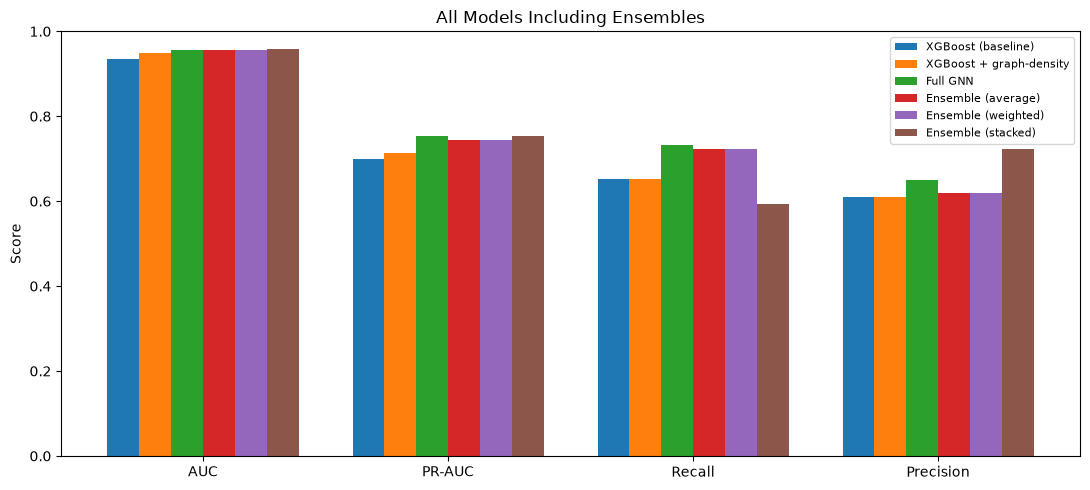

In [30]:
plt.figure(figsize=(11, 5))
x = np.arange(4)
width = 0.13
for i, row in ensemble_results.iterrows():
    vals = [row['AUC'], row['PR-AUC'], row['Recall (fraud)'], row['Precision (fraud)']]
    plt.bar(x + i * width, vals, width, label=row['Model'])
plt.xticks(x + width * 2.5, ['AUC', 'PR-AUC', 'Recall', 'Precision'])
plt.ylabel('Score'); plt.title('All Models Including Ensembles')
plt.legend(fontsize=8); plt.ylim(0, 1); plt.tight_layout(); plt.show()

## Final Combined Results Table

In [31]:
final_results = pd.DataFrame([
    baseline_metrics, graph_metrics, gnn_metrics,
    avg_metrics, weighted_metrics, stacked_metrics_clean
]).round(3)
print(final_results)


                       Model    AUC  PR-AUC  Recall (fraud)  Precision (fraud)
0         XGBoost (baseline)  0.936   0.699           0.653              0.611
1    XGBoost + graph-density  0.948   0.713           0.653              0.611
2                   Full GNN  0.956   0.753           0.733              0.649
3         Ensemble (average)  0.956   0.744           0.723              0.619
4        Ensemble (weighted)  0.956   0.745           0.723              0.619
5  Ensemble (stacked, clean)  0.968   0.798           0.720              0.643


# Saving artifacts for the dashboard

In [32]:
# ===== Save artifacts for the dashboard =====
import json, joblib
from pathlib import Path
from datetime import datetime

OUT = Path('artifacts'); OUT.mkdir(exist_ok=True)
THRESHOLD = 0.35
baseline_feat_cols = list(X.columns)
graph_feat_cols = list(X_graph.columns)

In [33]:
# --- 1. Models ---
baseline_model = XGBClassifier(
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    eval_metric='auc', random_state=42
)
baseline_model.fit(X_train[baseline_feat_cols], y_train)   # same split/seed as cell 15
baseline_model.save_model(OUT / 'xgb_baseline.json')
model.save_model(OUT / 'xgb_graph.json')                     # graph-augmented model from cell 27
torch.save(gnn_model.state_dict(), OUT / 'gnn_state.pt')
torch.save(data, OUT / 'hetero_data.pt')                     # scaled HeteroData graph, for live GNN explanations
joblib.dump(stacker_clean, OUT / 'stacker_clean.joblib')
joblib.dump({'provider': provider_id_map, 'beneficiary': bene_id_map, 'physician': phys_id_map},
            OUT / 'id_maps.joblib')

['artifacts/id_maps.joblib']

In [34]:
# --- 2. Per-provider table: features + label + split + every model's score ---
split = pd.Series('train', index=provider_features.index)
split[provider_features['Provider'].isin(set(val_ids))] = 'val'
split[X_test.index] = 'test'

scores = provider_features.copy()
scores['split'] = split
scores['p_xgb_baseline'] = baseline_model.predict_proba(X[baseline_feat_cols])[:, 1]
scores['p_xgb_graph'] = model.predict_proba(X_graph)[:, 1]
scores['p_gnn'] = gnn_probs_all                              # same row order as provider_features
three = scores[['p_xgb_baseline', 'p_xgb_graph', 'p_gnn']].values
scores['p_ens_avg'] = three.mean(axis=1)
scores['p_ens_weighted'] = three @ weights
scores['p_ens_stacked'] = stacker_clean.predict_proba(three)[:, 1]
scores['stack_eval'] = False                                 # rows the clean stacker was scored on
scores.loc[X_test.index[stack_idx_eval], 'stack_eval'] = True
scores.to_parquet(OUT / 'provider_scores.parquet', index=False)

In [35]:
# --- 3. SHAP for ALL providers (per-provider explanation in the dashboard) ---
for name, mdl, Xm in [('baseline', baseline_model, X[baseline_feat_cols]), ('graph', model, X_graph)]:
    ex = shap.TreeExplainer(mdl)
    sv = pd.DataFrame(ex.shap_values(Xm), columns=Xm.columns)
    sv.insert(0, 'Provider', provider_features['Provider'].values)
    sv.to_parquet(OUT / f'shap_{name}.parquet', index=False)
    json.dump({'expected_value': float(ex.expected_value)}, open(OUT / f'shap_{name}_base.json', 'w'))

In [36]:
# --- 4. Graph edges (aggregated, no duplicate edges) ---
claims.groupby(['Provider', 'BeneID']).agg(
    n_claims=('ClaimID', 'count'), total_reimbursed=('InscClaimAmtReimbursed', 'sum')
).reset_index().to_parquet(OUT / 'edges_provider_beneficiary.parquet', index=False)

claims[claims['AttendingPhysician'] != 'None'].groupby(['Provider', 'AttendingPhysician']).agg(
    n_claims=('ClaimID', 'count'), total_reimbursed=('InscClaimAmtReimbursed', 'sum')
).reset_index().to_parquet(OUT / 'edges_provider_physician.parquet', index=False)

In [38]:
# --- 5. Slim claims table (drill-down) ---
claims['ClaimDuration'] = (claims['ClaimEndDt'] - claims['ClaimStartDt']).dt.days
claim_cols = ['ClaimID', 'Provider', 'BeneID', 'ClaimType', 'ClaimStartDt', 'ClaimEndDt',
              'InscClaimAmtReimbursed', 'DeductibleAmtPaid', 'AttendingPhysician',
              'OperatingPhysician', 'OtherPhysician', 'num_diagnoses', 'num_procedures',
              'ClaimDuration', 'State', 'County', 'Gender', 'Race', 'PotentialFraud']
claims[claim_cols].to_parquet(OUT / 'claims_slim.parquet', index=False)

In [39]:
# --- 6. Metrics tables ---
final_results.to_csv(OUT / 'metrics_final.csv', index=False)
ensemble_results.to_csv(OUT / 'metrics_ensembles.csv', index=False)
pd.DataFrame([
    {'model': lbl, 'fold': f, **{m: cv[f'test_{m}'][f] for m in ['auc', 'pr_auc', 'recall', 'precision']}}
    for lbl, cv in [('XGBoost (baseline)', baseline_cv), ('XGBoost + graph-density', graph_cv)]
    for f in range(5)
]).to_csv(OUT / 'cv_folds.csv', index=False)

In [40]:
# --- 7. GNN edge-type ablation (per sampled fraud provider) ---
pd.DataFrame([
    {'relation': '->'.join([r[0], r[2]]), 'provider_pos': int(p), 'drop': d}
    for r in relations for p, d in zip(sample_positions, relation_drops[r])
]).to_csv(OUT / 'gnn_edge_ablation.csv', index=False)

In [41]:
# --- 8. Metadata ---
json.dump({
    'created': datetime.now().isoformat(timespec='seconds'),
    'threshold': THRESHOLD,
    'baseline_features': baseline_feat_cols,
    'graph_features': graph_feat_cols,
    'gnn_provider_features': list(provider_feat_cols),
    'gnn_hidden_channels': 64,
    'gnn_best_val_pr_auc': float(best_val_pr_auc),
    'ensemble_weights': dict(zip(['xgb_baseline', 'xgb_graph', 'gnn'], weights.round(4).tolist())),
    'split': {'test_size': 0.2, 'random_state': 42, 'val_frac_of_train': 0.15},
    'n_communities': len(communities),
    'graph': {'nodes': G.number_of_nodes(), 'edges': G.number_of_edges()},
}, open(OUT / 'metadata.json', 'w'), indent=2)

for f in sorted(OUT.iterdir()):
    print(f"{f.name:40s} {f.stat().st_size / 1e6:8.2f} MB")


claims_slim.parquet                         12.06 MB
cv_folds.csv                                 0.00 MB
edges_provider_beneficiary.parquet           2.47 MB
edges_provider_physician.parquet             0.90 MB
gnn_edge_ablation.csv                        0.00 MB
gnn_state.pt                                 0.02 MB
hetero_data.pt                              37.77 MB
id_maps.joblib                               3.62 MB
metadata.json                                0.00 MB
metrics_ensembles.csv                        0.00 MB
metrics_final.csv                            0.00 MB
provider_scores.parquet                      0.50 MB
shap_baseline.parquet                        0.39 MB
shap_baseline_base.json                      0.00 MB
shap_graph.parquet                           0.47 MB
shap_graph_base.json                         0.00 MB
stacker_clean.joblib                         0.00 MB
xgb_baseline.json                            0.34 MB
xgb_graph.json                               0